# Dissecting DETR

The DETR notebook shows how to *use* the DEtection TRansformer. This notebook takes `facebook/detr-resnet-50` apart
with PyTorch introspection — printing modules, counting parameters, and recording the shape of every tensor that flows
through it — to see how an image becomes 100 predictions, and how training matches predictions to objects.

DETR has three parts, built from **convolutions, (frozen) batch norms, layer norms, attention, and dense layers**:

- a **ResNet-50** CNN that turns the image into a grid of features 32 times smaller;
- a **Transformer encoder** that lets every grid position look at every other one;
- a **Transformer decoder** in which 100 learned *object queries* collect the information for one object each, and two
  small **heads** that turn each query into a class and a box.

A GPU makes section 6 faster (it runs the model on 300 images).

In [1]:
import re
import warnings
from concurrent.futures import ThreadPoolExecutor

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import torch
from huggingface_hub.utils import logging as hub_logging
from PIL import Image
from transformers import AutoImageProcessor, DetrForObjectDetection
from transformers.utils import logging as transformers_logging

transformers_logging.set_verbosity_error()
transformers_logging.disable_progress_bar()
hub_logging.set_verbosity_error()  # no warning about downloading without a Hugging Face login (not needed here)
warnings.filterwarnings("ignore", category=FutureWarning)  # deprecations inside the libraries
%config InlineBackend.figure_formats = ['jpeg']
%config InlineBackend.print_figure_kwargs = {'bbox_inches': 'tight', 'dpi': 144, 'pil_kwargs': {'quality': 85}}

device = "cuda" if torch.cuda.is_available() else "cpu"
COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]

model = DetrForObjectDetection.from_pretrained("facebook/detr-resnet-50").to(device).eval()
processor = AutoImageProcessor.from_pretrained("facebook/detr-resnet-50")
config = model.config


def load_coco(image_id: int) -> Image.Image:
    url = f"https://s3.us-east-1.amazonaws.com/images.cocodataset.org/val2017/{image_id:012d}.jpg"
    return Image.open(requests.get(url, stream=True).raw).convert("RGB")

## 1. The module tree

`print(model)` shows the nested `torch.nn.Module`s. Most of the printout is the ResNet-50 (a `timm` model); the
Transformer at the end is short because PyTorch collapses the repeated layers (`(0-5): 6 x DetrEncoderLayer`).

In [2]:
print(model)

DetrForObjectDetection(
  (model): DetrModel(
    (backbone): DetrConvEncoder(
      (model): FeatureListNet(
        (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
        (bn1): DetrFrozenBatchNorm2d()
        (act1): ReLU(inplace=True)
        (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
        (layer1): Sequential(
          (0): Bottleneck(
            (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
            (bn1): DetrFrozenBatchNorm2d()
            (act1): ReLU(inplace=True)
            (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
            (bn2): DetrFrozenBatchNorm2d()
            (drop_block): Identity()
            (act2): ReLU(inplace=True)
            (aa): Identity()
            (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
            (bn3): DetrFrozenBatchNorm2d()
            (act3): ReLU(inplace

The configuration values that determine the Transformer:

In [3]:
{"backbone": config.backbone_config.backbone} | {name: getattr(config, name) for name in [
    "d_model", "encoder_layers", "encoder_attention_heads", "encoder_ffn_dim", "decoder_layers",
    "decoder_attention_heads", "decoder_ffn_dim", "num_queries", "num_labels", "activation_function",
    "class_cost", "bbox_cost", "giou_cost", "eos_coefficient",
]}

{'backbone': 'resnet50',
 'd_model': 256,
 'encoder_layers': 6,
 'encoder_attention_heads': 8,
 'encoder_ffn_dim': 2048,
 'decoder_layers': 6,
 'decoder_attention_heads': 8,
 'decoder_ffn_dim': 2048,
 'num_queries': 100,
 'num_labels': 91,
 'activation_function': 'relu',
 'class_cost': 1,
 'bbox_cost': 5,
 'giou_cost': 2,
 'eos_coefficient': 0.1}

### Where the parameters are

In [4]:
def n_params(module) -> int:
    return sum(p.numel() for p in module.parameters())


detr = model.model
stages = {
    "backbone (ResNet-50)": [detr.backbone],
    "input_projection": [detr.input_projection],
    "encoder (6 layers)": [detr.encoder],
    "query_position_embeddings": [detr.query_position_embeddings],
    "decoder (6 layers)": [detr.decoder],
    "class_labels_classifier": [model.class_labels_classifier],
    "bbox_predictor": [model.bbox_predictor],
}
table = pd.DataFrame({"parameters": {name: sum(n_params(m) for m in ms) for name, ms in stages.items()}})
table.loc["total"] = n_params(model)
table["share"] = (table["parameters"] / n_params(model)).map("{:.1%}".format)
table

,parameters,share
backbone (ResNet-50),23454912,56.5%
input_projection,524544,1.3%
encoder (6 layers),7890432,19.0%
query_position_embeddings,25600,0.1%
decoder (6 layers),9473024,22.8%
class_labels_classifier,23644,0.1%
bbox_predictor,132612,0.3%
total,41524768,100.0%


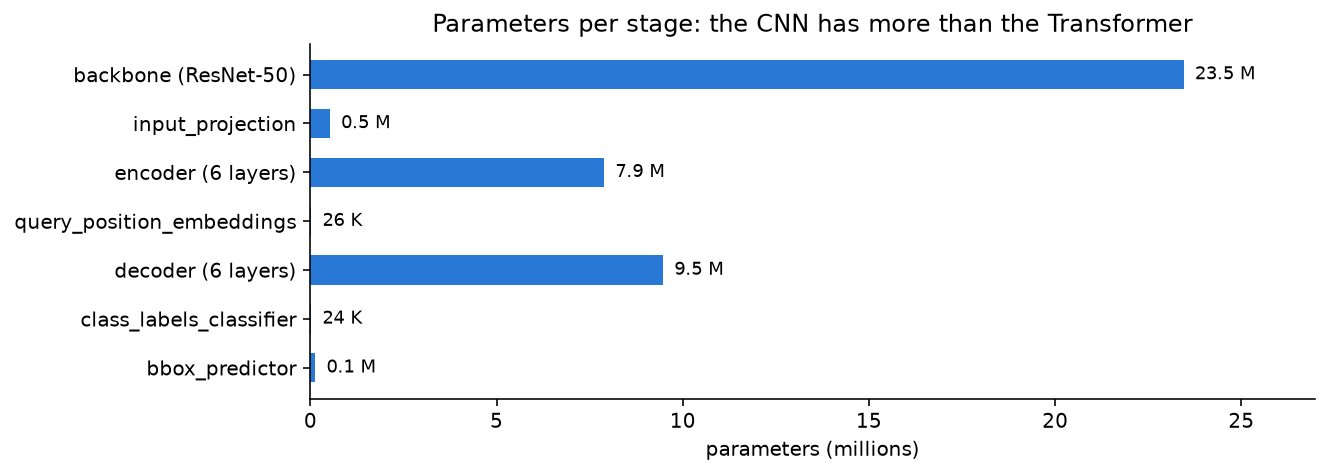

In [5]:
parts = table.drop(index="total")["parameters"][::-1] / 1e6
fig, ax = plt.subplots(figsize=(9, 3.2))
ax.barh(parts.index, parts.values, color=COLORS[0], height=0.6)
for y, v in enumerate(parts.values):
    ax.text(v + 0.3, y, f"{v:.1f} M" if v >= 0.1 else f"{v * 1e3:.0f} K", va="center", fontsize=9)
ax.set(xlabel="parameters (millions)", title="Parameters per stage: the CNN has more than the Transformer",
       xlim=(0, parts.max() * 1.15))
ax.spines[["top", "right"]].set_visible(False)
plt.show()

In [6]:
by_type = {}
for name, module in model.named_modules():
    own = sum(p.numel() for p in module.parameters(recurse=False))
    frozen = sum(b.numel() for b in module.buffers(recurse=False))
    if own or frozen:
        count, total, fixed = by_type.get(type(module).__name__, (0, 0, 0))
        by_type[type(module).__name__] = (count + 1, total + own, fixed + frozen)

pd.DataFrame(by_type, index=["modules", "parameters", "fixed values (buffers)"]).T.sort_values("parameters", ascending=False)

,modules,parameters,fixed values (buffers)
Conv2d,54,23979456,0
Linear,100,17503840,0
Embedding,1,25600,0
LayerNorm,31,15872,0
DetrFrozenBatchNorm2d,53,0,106240


The batch norms of the ResNet are **frozen** (`DetrFrozenBatchNorm2d`): their mean, variance, scale and shift are
fixed numbers (*buffers*) from ImageNet pre-training, not parameters. Detection is trained with small batches of large
images, too small for good batch statistics, so DETR keeps the ImageNet ones.

## 2. Tracing shapes with forward hooks

The cats image from the DETR notebook, resized by the processor to 800 × 1066. We register a hook on every basic block
and run the model once.

In [7]:
cats = load_coco(39769)
inputs = processor(images=cats, return_tensors="pt").to(device)
BASIC = (torch.nn.Conv2d, torch.nn.MaxPool2d, torch.nn.LayerNorm, torch.nn.Linear, torch.nn.ReLU)
records = []


def first_tensor(x):
    while isinstance(x, (tuple, list)):
        x = x[0]
    return x


def make_hook(name):
    def hook(module, args, kwargs, output):
        x = args[0] if args else next(iter(kwargs.values()))
        records.append({"module": name, "type": type(module).__name__, "input": tuple(first_tensor(x).shape),
                        "output": tuple(first_tensor(output).shape),
                        "parameters": 0 if "Attention" in type(module).__name__ else n_params(module)})
    return hook


handles = [m.register_forward_hook(make_hook(n), with_kwargs=True) for n, m in model.named_modules()
           if isinstance(m, BASIC) or type(m).__name__ in ("DetrFrozenBatchNorm2d", "DetrSelfAttention", "DetrCrossAttention")]
with torch.no_grad():
    outputs = model(**inputs)
for h in handles:
    h.remove()

trace = pd.DataFrame(records)
print(len(trace), "calls of", trace["module"].nunique(), "modules")

318 calls of 318 modules


The 6 encoder layers are identical, and so are the 6 decoder layers. The ResNet's stages are kept: within a
stage, the blocks differ (the first one changes the size and has a `downsample` branch), so we show the first two
blocks of each stage and the stage's output.

In [8]:
trace["stack"] = trace["module"].str.extract(r"^(.*\.layers)\.\d+\.")[0]
trace["layer"] = trace["module"].str.extract(r"\.layers\.(\d+)\.")[0]
for stack, rows in trace.dropna(subset="layer").groupby("stack"):
    per_layer = [g[["type", "input", "output", "parameters"]].reset_index(drop=True) for _, g in rows.groupby("layer")]
    assert all(p.equals(per_layer[0]) for p in per_layer), stack

block = trace["module"].str.extract(r"backbone\.model\.layer\d\.(\d+)\.")[0].astype(float)
keep = (trace["layer"].isna() | (trace["layer"] == "0")) & ~(block >= 2)
collapsed = trace[keep].drop(columns=["stack", "layer"]).copy()
collapsed["module"] = collapsed["module"].str.replace(r"\.layers\.0\.", ".layers.*.", regex=True)
with pd.option_context("display.max_rows", 200, "display.max_colwidth", 70):
    display(collapsed.reset_index(drop=True))

,module,type,input,output,parameters
0,model.backbone.model.conv1,Conv2d,"(1, 3, 800, 1066)","(1, 64, 400, 533)",9408
1,model.backbone.model.bn1,DetrFrozenBatchNorm2d,"(1, 64, 400, 533)","(1, 64, 400, 533)",0
2,model.backbone.model.act1,ReLU,"(1, 64, 400, 533)","(1, 64, 400, 533)",0
3,model.backbone.model.maxpool,MaxPool2d,"(1, 64, 400, 533)","(1, 64, 200, 267)",0
4,model.backbone.model.layer1.0.conv1,Conv2d,"(1, 64, 200, 267)","(1, 64, 200, 267)",4096
5,model.backbone.model.layer1.0.bn1,DetrFrozenBatchNorm2d,"(1, 64, 200, 267)","(1, 64, 200, 267)",0
6,model.backbone.model.layer1.0.act1,ReLU,"(1, 64, 200, 267)","(1, 64, 200, 267)",0
7,model.backbone.model.layer1.0.conv2,Conv2d,"(1, 64, 200, 267)","(1, 64, 200, 267)",36864
8,model.backbone.model.layer1.0.bn2,DetrFrozenBatchNorm2d,"(1, 64, 200, 267)","(1, 64, 200, 267)",0
9,model.backbone.model.layer1.0.act2,ReLU,"(1, 64, 200, 267)","(1, 64, 200, 267)",0


Reading the table top to bottom:

- The ResNet halves the resolution 5 times (stride 32): 800 × 1066 → **25 × 34** positions with 2048 channels.
- `input_projection` (a 1 × 1 convolution) reduces 2048 to 256 channels; the 25 × 34 grid is flattened into a sequence
  of **850 tokens**.
- The encoder keeps 850 tokens of 256 dimensions through its 6 layers.
- The decoder works on **100** vectors, one per query. In its `encoder_attn`, `q_proj` gets the 100 queries and
  `k_proj`, `v_proj` the 850 encoder tokens.
- `class_labels_classifier` gives 92 scores per query, `bbox_predictor` (3 `Linear` layers) 4 numbers.

### The architecture as a diagram

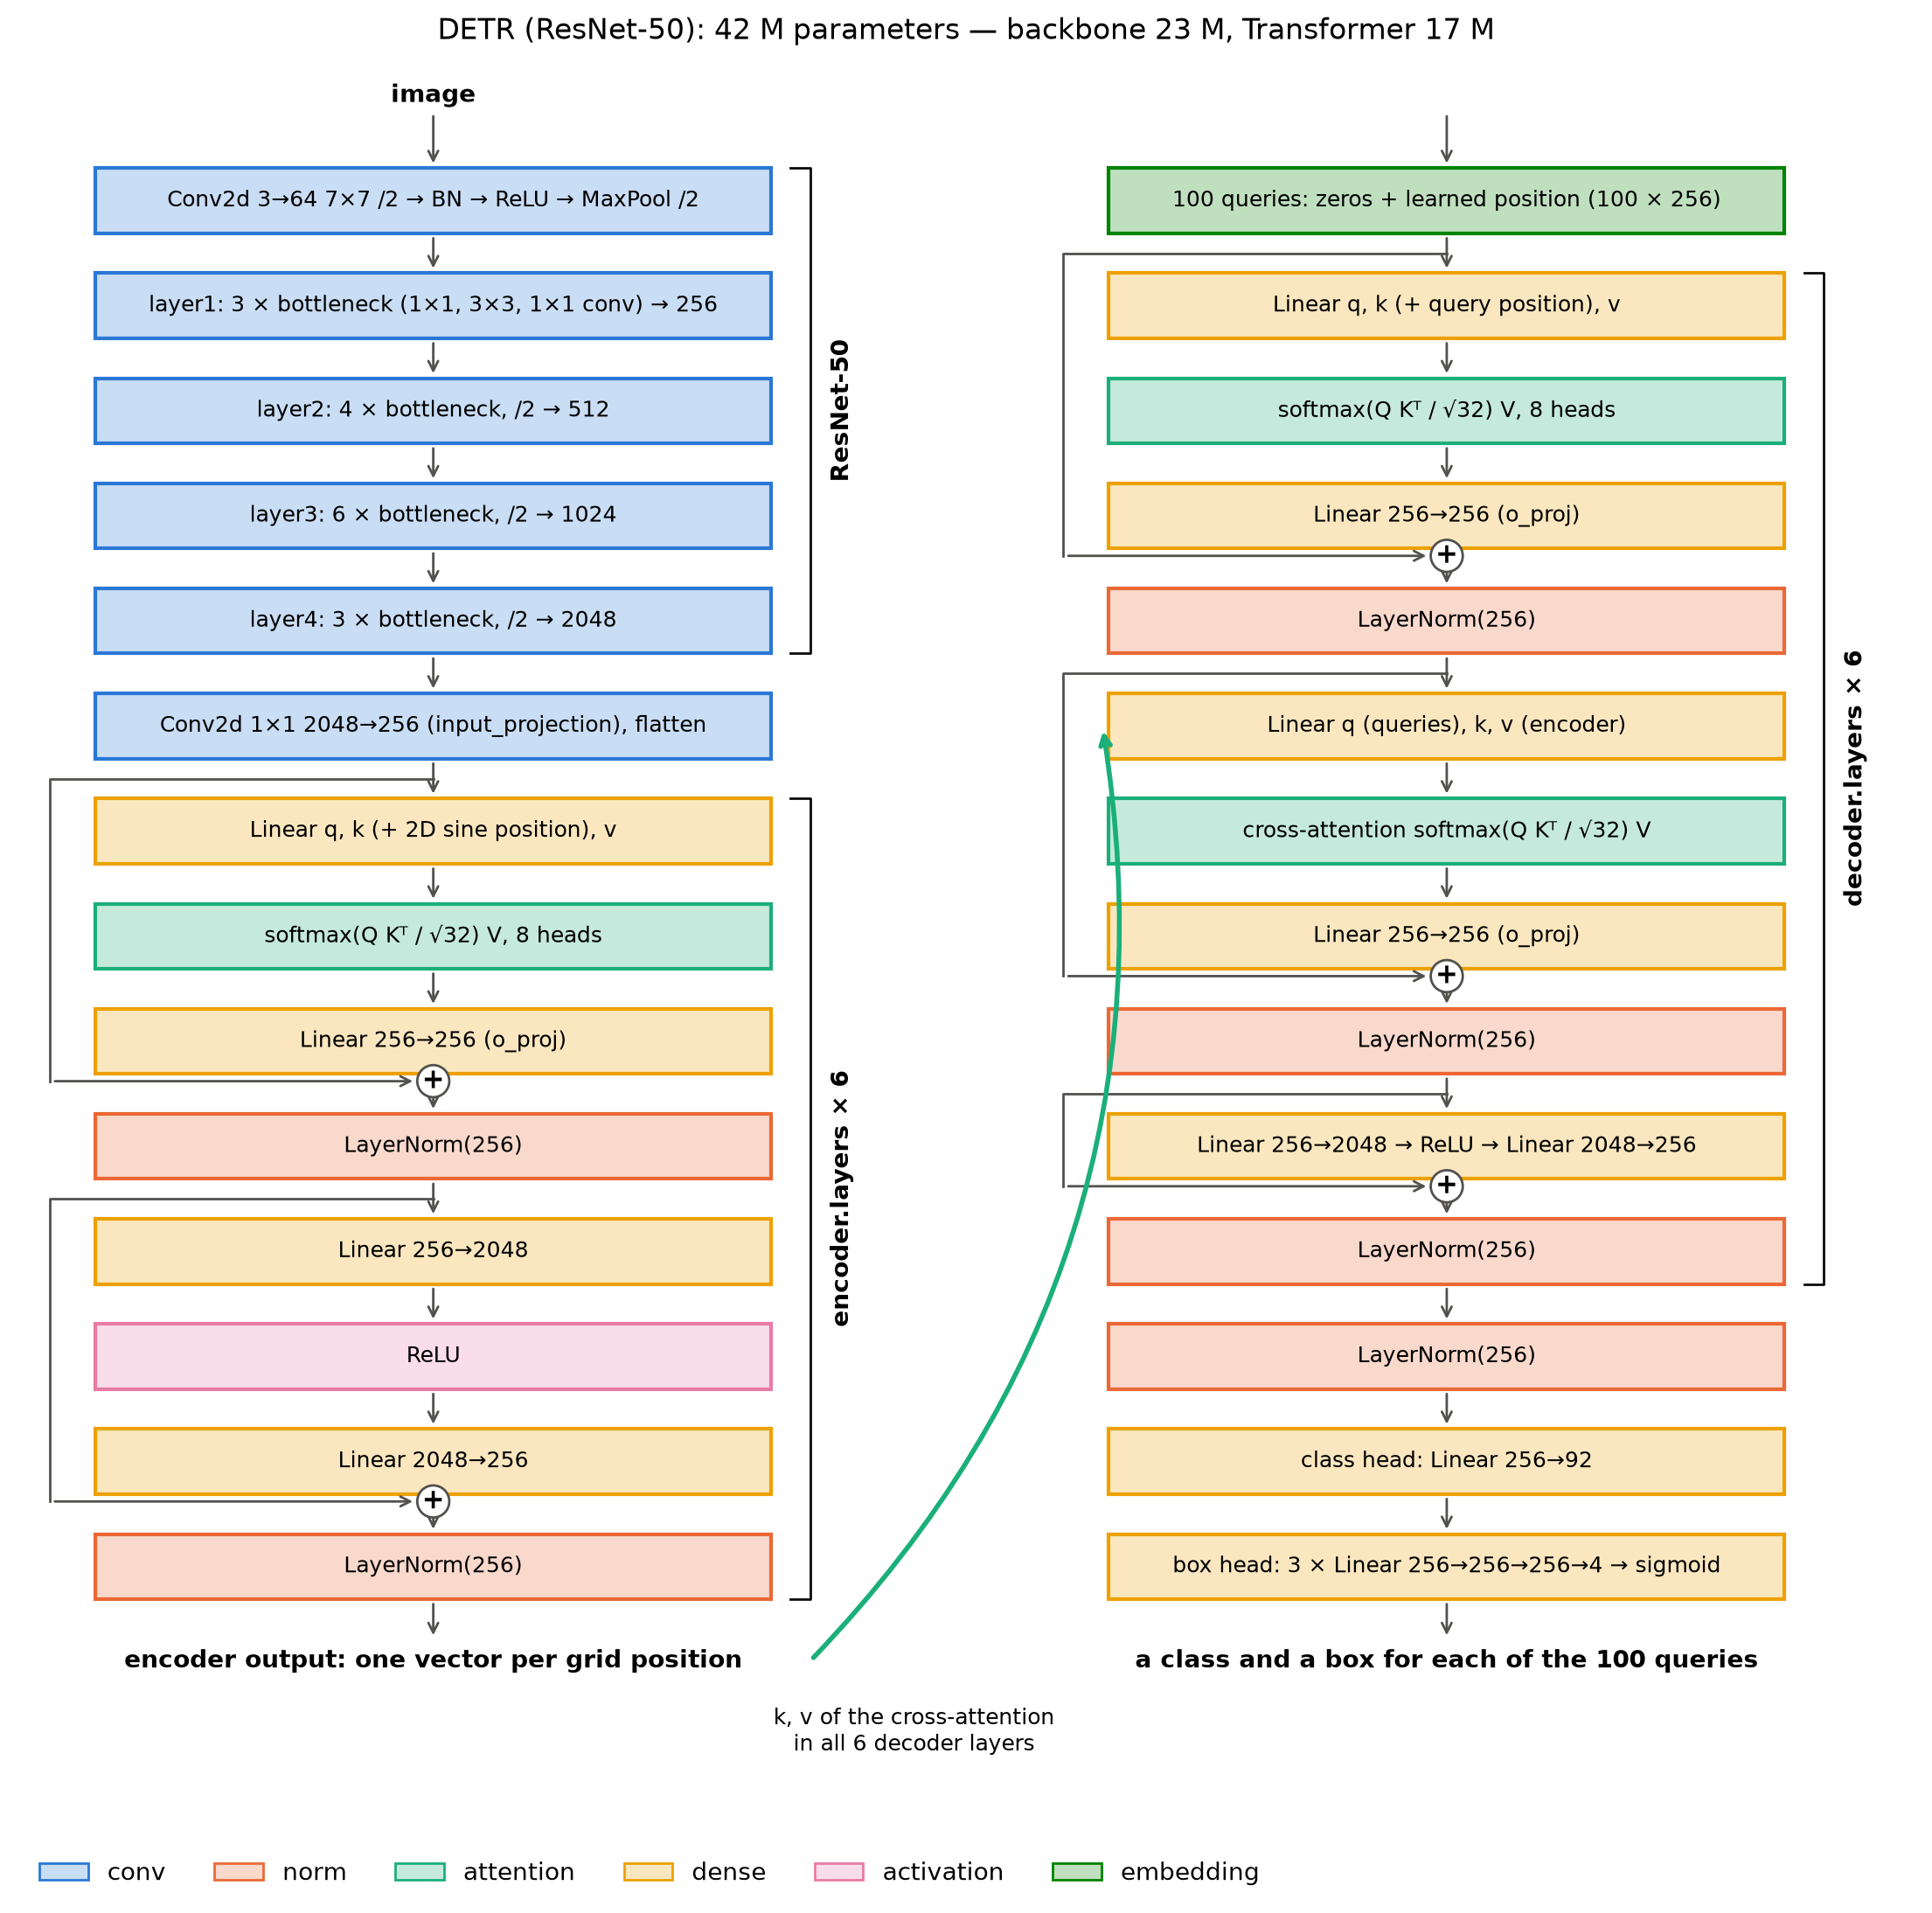

## 3. The CNN backbone

ResNet-50 (He et al. 2015, see module 2) is a stack of **bottleneck** blocks: a 1 × 1 convolution reduces the
channels, a 3 × 3 convolution works on the smaller representation, a 1 × 1 convolution expands the channels again,
and the block's input is added to its output (a residual connection). DETR uses the ImageNet-trained ResNet and keeps
only its last feature map.

The 256 channels after `input_projection`, projected onto their 3 main directions (PCA) as red, green, blue:

backbone output: (1, 2048, 25, 34)  projected: (256, 25, 34)


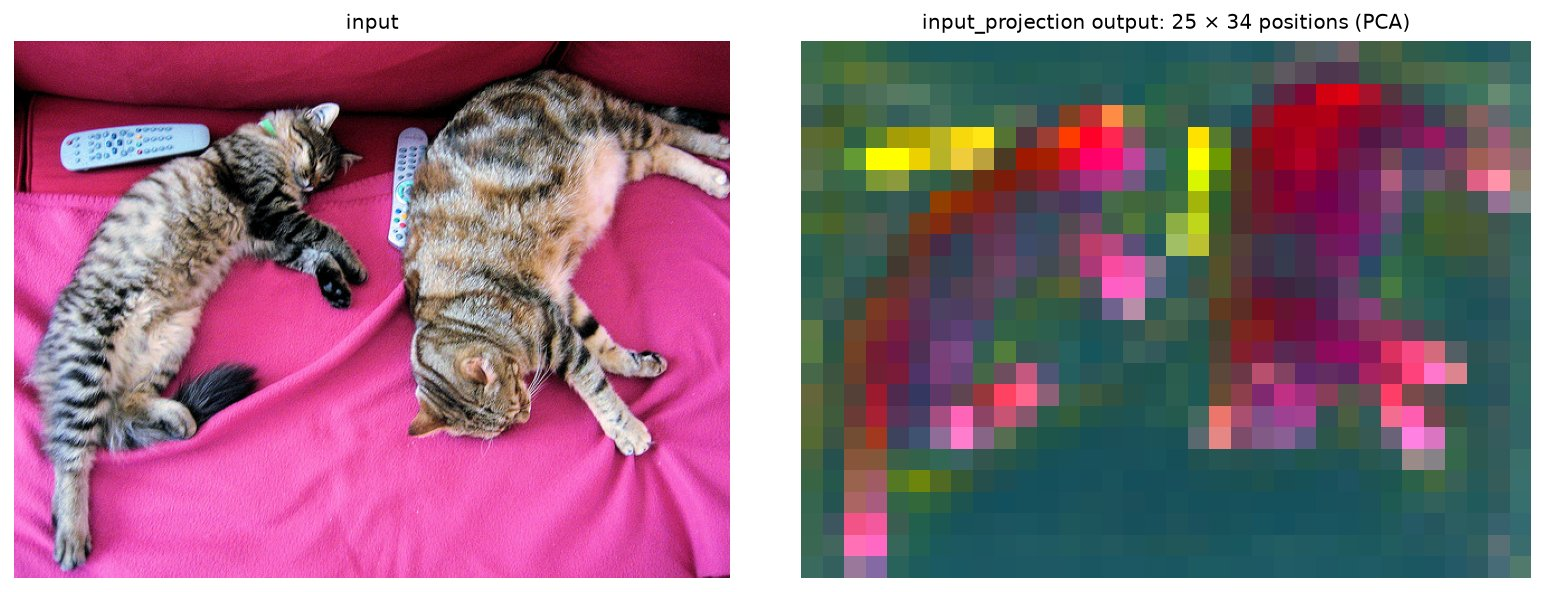

In [9]:
with torch.no_grad():
    feature_map, mask = detr.backbone(inputs["pixel_values"], inputs["pixel_mask"])[-1]
    projected = detr.input_projection(feature_map)[0]                       # (256, 25, 34)
print("backbone output:", tuple(feature_map.shape), " projected:", tuple(projected.shape))


def pca_rgb(features):
    c, h, w = features.shape
    x = features.reshape(c, -1).T.float()
    x = x - x.mean(dim=0)
    _, _, v = torch.pca_lowrank(x, q=3, center=False)
    rgb = (x @ v[:, :3]).reshape(h, w, 3)
    return ((rgb - rgb.quantile(0.01)) / (rgb.quantile(0.99) - rgb.quantile(0.01))).clamp(0, 1).cpu().numpy()


fig, axes = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")
axes[0].imshow(cats)
axes[0].set_title("input", fontsize=10)
axes[1].imshow(pca_rgb(projected))
axes[1].set_title("input_projection output: 25 × 34 positions (PCA)", fontsize=10)
for ax in axes:
    ax.axis("off")
plt.show()

## 4. Positions: 2D sine encoding

Attention by itself doesn't know where a token is. DETR encodes each position $(y, x)$ of the 25 × 34 grid with sines
and cosines, like the original Transformer but in 2D: 128 channels for $y$ and 128 for $x$, with
$y, x$ normalized to $[0, 2\pi]$:

$$\mathrm{PE}_{2i}(p) = \sin\!\left(\frac{p}{10000^{2i/128}}\right) \qquad \mathrm{PE}_{2i+1}(p) = \cos\!\left(\frac{p}{10000^{2i/128}}\right)$$

The encoding is not added to the tokens once at the start, but to the **queries and keys** of every attention layer
(not to the values) — so the attention weights know the positions, while what is passed on stays the content. Some
channels, as images over the grid:

position encoding: (256, 25, 34) (channels, height, width)


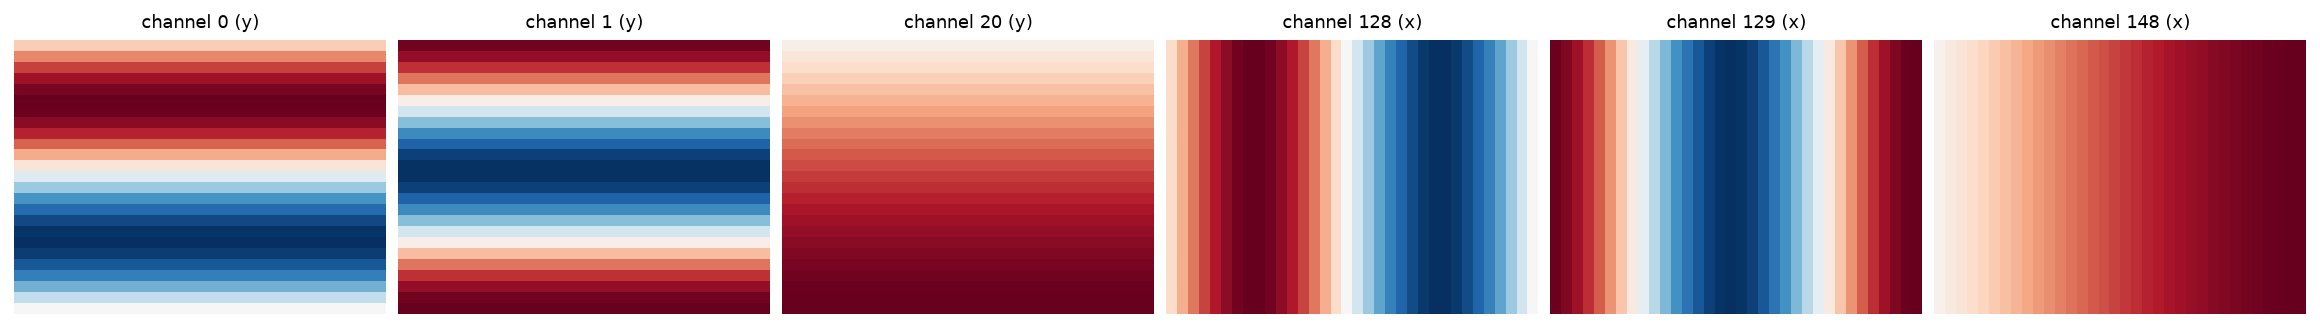

In [10]:
with torch.no_grad():
    position = detr.position_embedding(shape=feature_map.shape, device=device, dtype=feature_map.dtype, mask=mask)[0]
print("position encoding:", tuple(position.shape), "(channels, height, width)")

fig, axes = plt.subplots(1, 6, figsize=(16, 2.4), layout="constrained")
for ax, channel in zip(axes, [0, 1, 20, 128, 129, 148]):
    ax.imshow(position[channel].cpu(), cmap="RdBu_r", vmin=-1, vmax=1)
    ax.set_title(f"channel {channel} ({'y' if channel < 128 else 'x'})", fontsize=9)
    ax.axis("off")
plt.show()

## 5. Encoder and decoder layers

Both use the **post-norm** layout of the original Transformer (normalize after each residual addition). With $p$ the
sine positions of the 850 tokens and $q_\text{pos}$ the learned positions of the 100 queries:

$$\text{encoder:}\qquad h = \mathrm{LN}\big(x + \mathrm{Attn}(Q = x + p,\ K = x + p,\ V = x)\big) \qquad y = \mathrm{LN}\big(h + \mathrm{MLP}(h)\big)$$

$$\text{decoder:}\qquad h = \mathrm{LN}\big(z + \mathrm{Attn}(z + q_\text{pos},\ z + q_\text{pos},\ z)\big) \qquad g = \mathrm{LN}\big(h + \mathrm{Attn}(h + q_\text{pos},\ e + p,\ e)\big) \qquad y = \mathrm{LN}\big(g + \mathrm{MLP}(g)\big)$$

$e$ is the encoder output and $z$ the decoder's input, which starts as **zeros**: before the first layer, the 100
queries differ only in their learned positions $q_\text{pos}$ (`query_position_embeddings`, 100 × 256). The decoder's
self-attention lets the queries coordinate, so that two of them don't report the same object. There is no causal mask:
all 100 predictions are made at once.

In [11]:
with torch.no_grad():
    outputs = model(**inputs, output_hidden_states=True)
print("decoder input is all zeros:", bool((outputs.decoder_hidden_states[0] == 0).all()))
print("query positions:", tuple(detr.query_position_embeddings.weight.shape))

decoder input is all zeros: True
query positions: (100, 256)


## 6. What the object queries specialize in

Each query learns to look for objects in a particular region and of a particular size. Running the model on
300 COCO validation images and plotting **all** boxes that a query predicts (whether or not it's confident) shows
its "specialty": the centers of its boxes, colored by the box shape.

In [12]:
COCO_IDS = [139, 285, 632, 724, 776, 785, 802, 872, 885, 1000, 1268, 1296, 1353, 1425, 1490, 1503, 1532, 1584, 1675, 1761,
           1818, 1993, 2006, 2149, 2153, 2157, 2261, 2299, 2431, 2473, 2532, 2587, 2592, 2685, 2923, 3156, 3255,
           3501, 3553, 3661, 3845, 3934, 4134, 4395, 4495, 4765, 4795, 5001, 5037, 5060, 5193, 5477, 5503, 5529,
           5586, 5600, 5992, 6012, 6040, 6213, 6460, 6471, 6614, 6723, 6763, 6771, 6818, 6894, 6954, 7088, 7108,
           7278, 7281, 7386, 7511, 7574, 7784, 7795, 7816, 7818, 7888, 7977, 7991, 8021, 8211, 8277, 8532, 8629,
           8690, 8762, 8844, 8899, 9378, 9400, 9448, 9483, 9590, 9769, 9772, 9891, 9914, 10092, 10363, 10583,
           10707, 10764, 10977, 10995, 11051, 11122, 11149, 11197, 11511, 11615, 11699, 11760, 11813, 12062, 12120,
           12280, 12576, 12639, 12667, 12670, 12748, 13004, 13177, 13201, 13291, 13348, 13546, 13597, 13659, 13729,
           13774, 13923, 14007, 14038, 14226, 14380, 14439, 14473, 14831, 14888, 15079, 15254, 15272, 15278, 15335,
           15338, 15440, 15497, 15517, 15597, 15660, 15746, 15751, 15956, 16010, 16228, 16249, 16439, 16451, 16502,
           16598, 16958, 17029, 17031, 17115, 17178, 17182, 17207, 17379, 17436, 17627, 17714, 17899, 17905, 17959,
           18150, 18193, 18380, 18491, 18519, 18575, 18737, 18770, 18833, 18837, 19042, 19109, 19221, 19402, 19432,
           19742, 19786, 19924, 20059, 20107, 20247, 20333, 20553, 20571, 20992, 21167, 21465, 21503, 21604, 21839,
           21879, 21903, 22192, 22371, 22396, 22479, 22589, 22623, 22705, 22755, 22892, 22935, 22969, 23023, 23034,
           23126, 23230, 23272, 23359, 23666, 23751, 23781, 23899, 23937, 24021, 24027, 24144, 24243, 24567, 24610,
           24919, 25057, 25096, 25139, 25181, 25228, 25386, 25393, 25394, 25424, 25560, 25593, 25603, 25986, 26204,
           26465, 26564, 26690, 26926, 26941, 27186, 27620, 27696, 27768, 27932, 27972, 27982, 28285, 28449, 28452,
           28809, 28993, 29187, 29393, 29397, 29596, 29640, 29675, 29984, 30213, 30494, 30504, 30675, 30785, 30828,
           31050, 31093, 31118, 31217, 31248, 31269, 31296, 31322, 31620, 31735, 31749, 31817, 32038, 32081, 32285,
           32334]

with ThreadPoolExecutor(16) as pool:
    coco_images = list(pool.map(load_coco, COCO_IDS))

all_boxes, all_scores = [], []
with torch.no_grad():
    for image in coco_images:
        result = model(**processor(images=image, return_tensors="pt").to(device))
        all_boxes.append(result.pred_boxes[0].cpu())
        all_scores.append(result.logits[0].softmax(-1)[:, :-1].max(-1).values.cpu())
all_boxes, all_scores = torch.stack(all_boxes), torch.stack(all_scores)     # (300, 100, 4), (300, 100)
print("boxes:", tuple(all_boxes.shape), " detections above 0.7 per image:", f"{(all_scores > 0.7).sum(1).float().mean():.1f}")

boxes: (300, 100, 4)  detections above 0.7 per image: 9.1


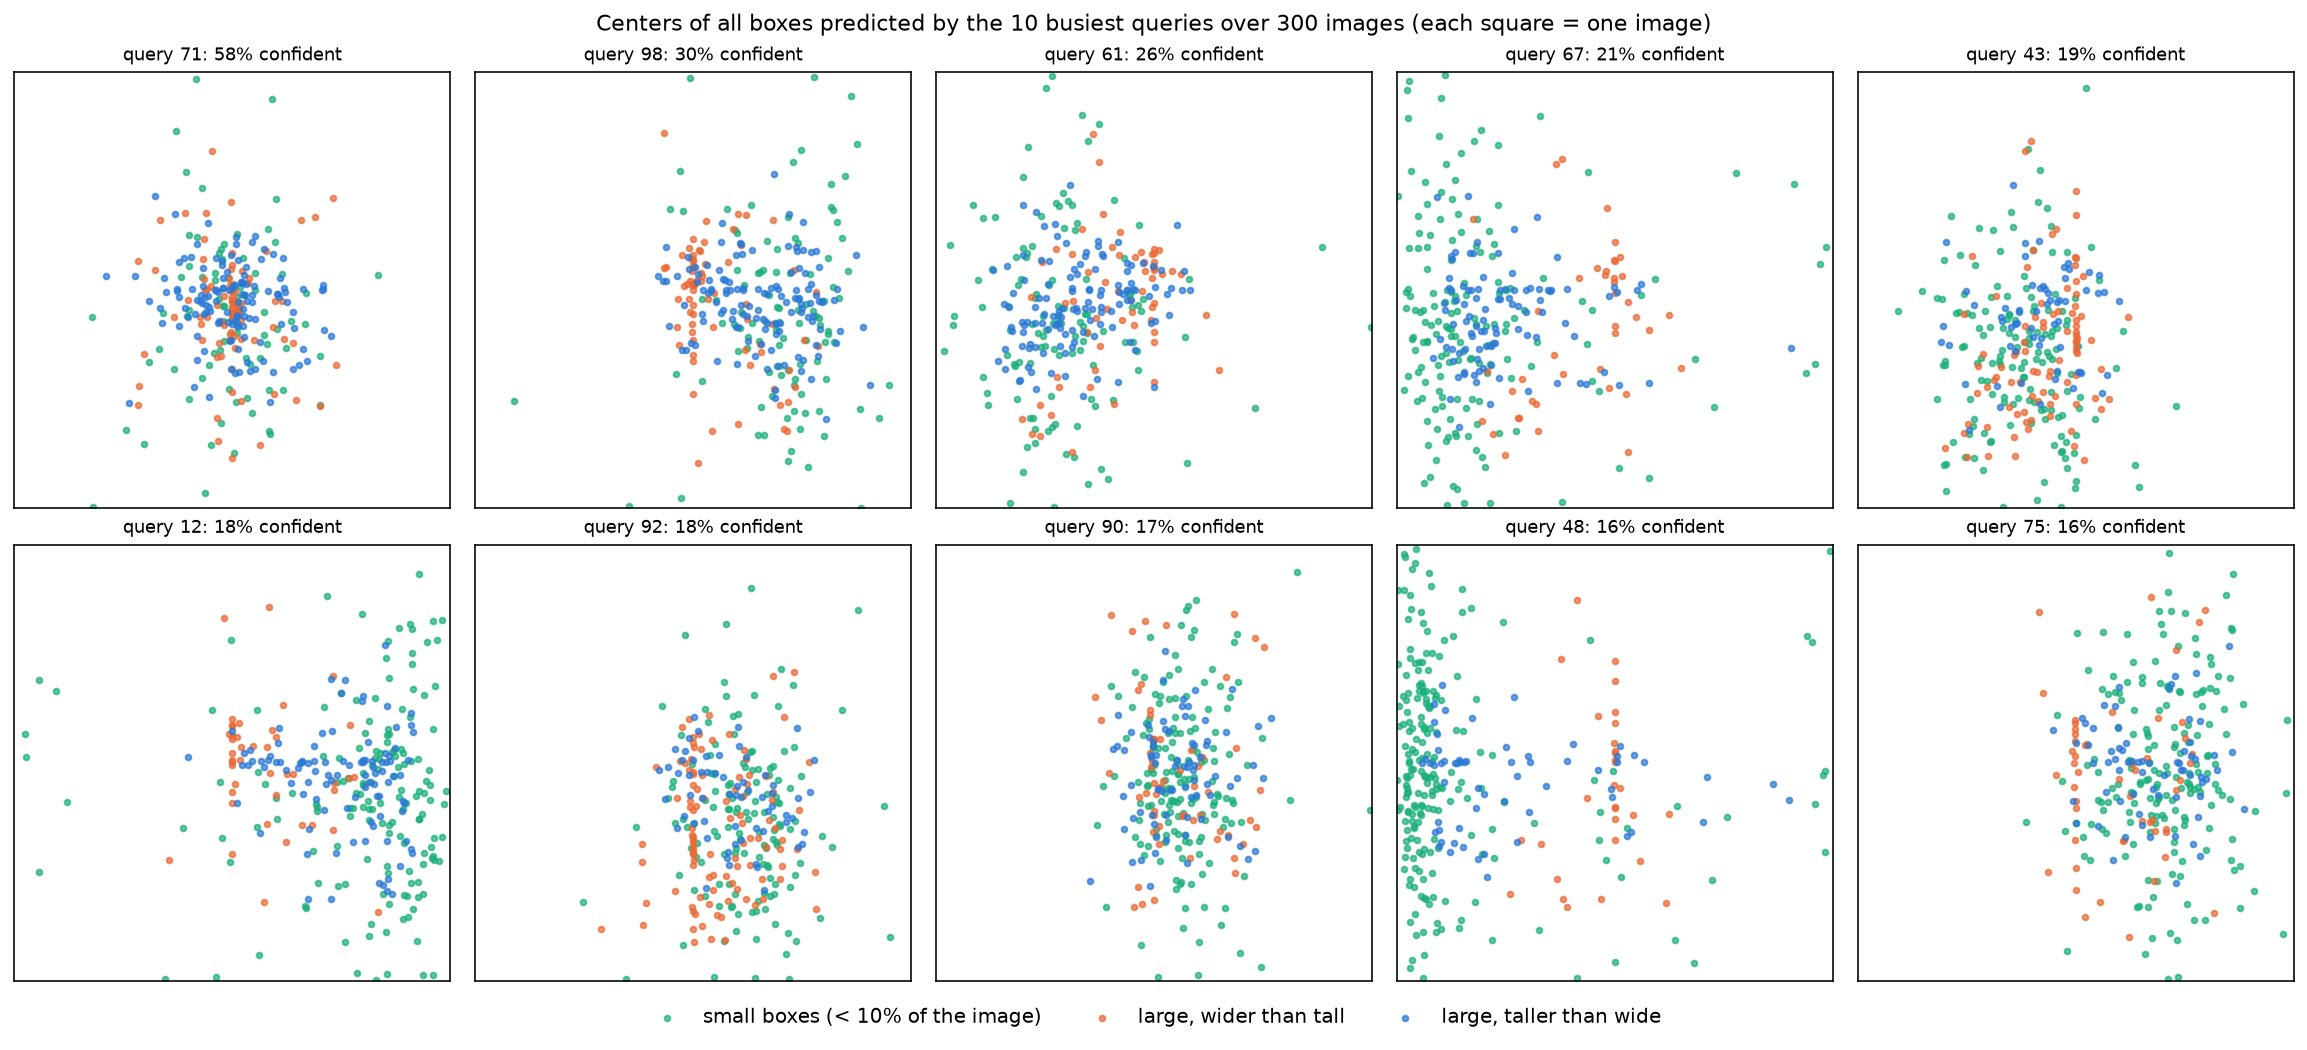

In [13]:
busiest = (all_scores > 0.7).float().mean(0).argsort(descending=True)[:10]
area = all_boxes[..., 2] * all_boxes[..., 3]
kind = np.where(area < 0.1, 0, np.where(all_boxes[..., 2] >= all_boxes[..., 3], 1, 2))     # small / wide / tall
names = ["small boxes (< 10% of the image)", "large, wider than tall", "large, taller than wide"]

fig, axes = plt.subplots(2, 5, figsize=(16, 6.8), layout="constrained")
for ax, query in zip(axes.flat, busiest.tolist()):
    for k, color in enumerate([COLORS[2], COLORS[1], COLORS[0]]):
        chosen = kind[:, query] == k
        ax.scatter(all_boxes[chosen, query, 0], all_boxes[chosen, query, 1], s=8, color=color, alpha=0.7,
                   label=names[k] if query == busiest[0] else None)
    ax.set(xlim=(0, 1), ylim=(1, 0), aspect="equal", xticks=[], yticks=[])
    ax.set_title(f"query {query}: {(all_scores[:, query] > 0.7).float().mean():.0%} confident", fontsize=9)
fig.legend(loc="lower center", ncols=3, frameon=False, bbox_to_anchor=(0.5, -0.06))
fig.suptitle("Centers of all boxes predicted by the 10 busiest queries over 300 images (each square = one image)",
             fontsize=11)
plt.show()

Each query has a home region: queries 67 and 48 the left edge, 12 the right, 71 and 61 the center. Within its
region a query predicts boxes of all sizes, some with a preference (48 mostly small boxes). Together, the 100 queries
cover the image — the regions are learned from the data, not designed by hand like the anchors of earlier detectors.

## 7. Training: one-to-one matching

To compute the loss, each ground-truth object is assigned to exactly one of the 100 queries. The cost of assigning
object $j$ to query $i$ combines how much the query believes in the object's class and how well the boxes agree:

$$C_{ij} = -1 \cdot p_i(c_j) \;+\; 5 \cdot \lVert b_i - b_j \rVert_1 \;-\; 2 \cdot \mathrm{GIoU}(b_i, b_j)$$

and the **Hungarian algorithm** (`scipy.optimize.linear_sum_assignment`) finds the assignment with the smallest total
cost. Queries without an object are trained to predict "no object". The cost matrix for the 6 annotated objects of
the cats image:

In [14]:
from scipy.optimize import linear_sum_assignment
from transformers.loss.loss_for_object_detection import HungarianMatcher, center_to_corners_format, generalized_box_iou

width, height = cats.size
annotations = [  # COCO val2017 image 39769: category id, box (x0, y0, width, height) in pixels
    (75, [332.9, 79.6, 38.6, 106.3]), (75, [41.9, 74.2, 133.2, 45.1]), (63, [1.1, 0.0, 638.6, 473.5]),
    (65, [1.1, 1.2, 638.9, 477.9]), (17, [17.5, 54.4, 301.2, 415.0]), (17, [347.5, 25.6, 292.5, 343.8]),
]
classes = torch.tensor([c for c, _ in annotations], device=device)
boxes = torch.tensor([[(x0 + w / 2) / width, (y0 + h / 2) / height, w / width, h / height]
                      for _, (x0, y0, w, h) in annotations], device=device)
names = [f"{config.id2label[c]} {k}" for k, (c, _) in enumerate(annotations)]

with torch.no_grad():
    probabilities = outputs.logits[0].softmax(-1)                                    # (100, 92)
    cost = (-1 * probabilities[:, classes]
            + 5 * torch.cdist(outputs.pred_boxes[0], boxes, p=1)
            - 2 * generalized_box_iou(center_to_corners_format(outputs.pred_boxes[0]), center_to_corners_format(boxes)))
queries, objects = linear_sum_assignment(cost.cpu().numpy())

matcher = HungarianMatcher(class_cost=1, bbox_cost=5, giou_cost=2)
reference = matcher({"logits": outputs.logits, "pred_boxes": outputs.pred_boxes}, [{"class_labels": classes, "boxes": boxes}])
print("same assignment as the model's HungarianMatcher:", sorted(zip(queries, objects)) ==
      sorted(zip(reference[0][0].tolist(), reference[0][1].tolist())))
pd.DataFrame({"object": [names[j] for j in objects], "query": queries, "cost": cost[queries, objects].cpu().numpy().round(2)})

same assignment as the model's HungarianMatcher: True


,object,query,cost
0,remote 1,37,-2.71
1,remote 0,57,-2.51
2,couch 2,59,-2.96
3,cat 4,61,-2.84
4,bed 3,72,-1.98
5,cat 5,98,-2.92


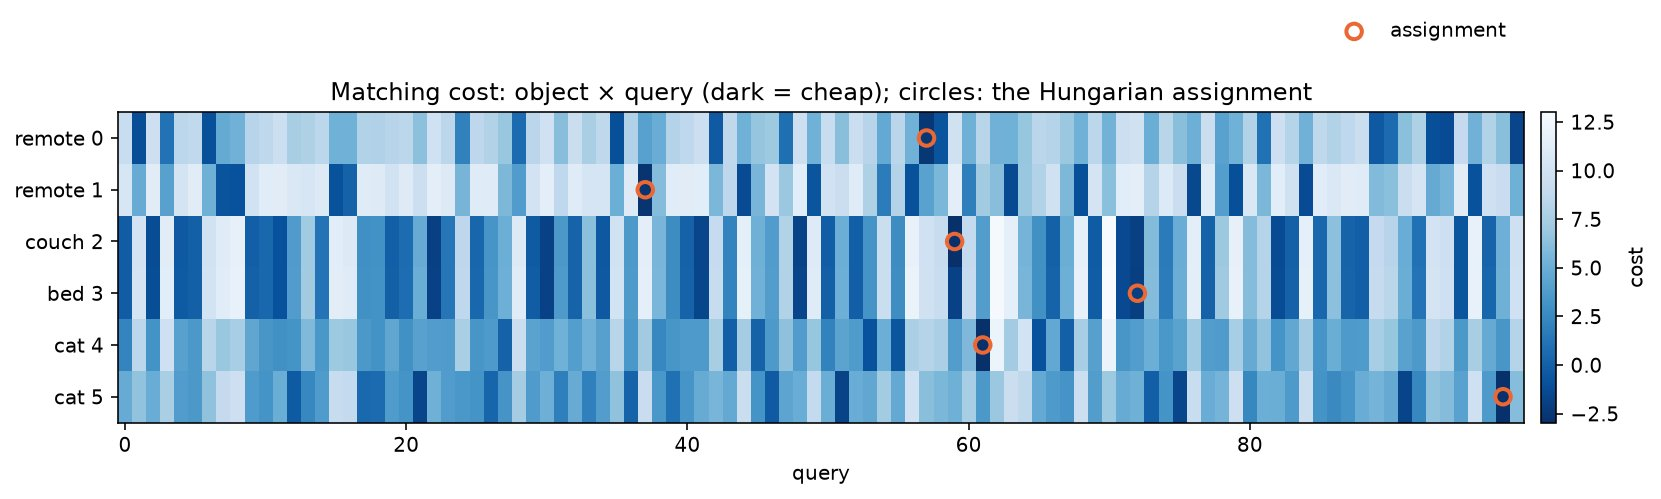

In [15]:
fig, ax = plt.subplots(figsize=(15, 2.8))
image = ax.imshow(cost.T.cpu(), cmap="Blues_r", aspect="auto", interpolation="nearest")
ax.scatter(queries, objects, marker="o", s=60, facecolor="none", edgecolor=COLORS[1], lw=2, label="assignment")
ax.set_yticks(range(len(names)), names)
ax.set(xlabel="query", title="Matching cost: object × query (dark = cheap); circles: the Hungarian assignment")
ax.legend(loc="upper right", bbox_to_anchor=(1, 1.35), frameon=False)
fig.colorbar(image, ax=ax, label="cost", pad=0.01)
plt.show()

The bed and the couch have almost the same box, so both rows are cheap for the same query; the one-to-one
assignment gives query 59 to the couch (which it predicts) and the bed to query 72 — its box also covers the whole
image, but it says "no object" (91%; "bed" only 8%). This is why the bed is the one missed object in the DETR
notebook, and in training this mismatch is exactly what the loss would push to fix.

## Summary

- **Backbone**: ResNet-50 (frozen batch norms) → 2048 × 25 × 34 → 1 × 1 conv → 850 tokens of 256;
- **Encoder**: 6 post-norm layers; 2D sine positions added to queries and keys in every layer;
- **Decoder**: 100 queries (zeros + learned positions) → 6 layers of self-attention, cross-attention to the encoder,
  MLP; the queries specialize in regions and sizes;
- **Heads**: `Linear` → 92 class scores (incl. "no object"), 3-layer MLP → box; trained with a one-to-one Hungarian
  matching of predictions to objects.